# Topik 3 v6: Mengejar macro-F1 0,65 (ensemble, bias kelas, hybrid multislice, train+val)

Hasil v5: CV 5-fold model terbaik sudah 0,653, tetapi test (171 data) baru 0,57–0,64. v6 mencoba 4 cara:

1. **Ensemble lintas pendekatan**: rata-rata probabilitas 2D, multislice, 3D, hybrid, dan model fitur (kesalahannya berbeda-beda).
2. **Penyesuaian bias per kelas**: mendorong kelas yang recall-nya rendah (hypo/iso), karena macro-F1 menghitung tiap kelas sama berat.
3. **Hybrid multislice + fitur**: gabungan komponen gambar dengan test terbaik (multislice) dan fitur intensitas.
4. **Training ulang di train+val**: data training +22%, jumlah epoch dari CV.

**Aturan main:** semua pilihan diambil dari prediksi out-of-fold 5-fold CV di train+val. Skor CV dihitung **nested** supaya jujur.
Data test hanya dilihat **sekali** di bagian 13. Run v5 dipakai ulang, jadi hanya eksperimen baru yang dilatih.

**Pengaturan Kaggle:** GPU T4, Internet On. Input: **notebook ekstraksi `topik-3`** dan **notebook v5 (`Topik 3 - Week 5`)**.
Jalankan dengan Save Version → Save & Run All. Estimasi ±2 jam (±1 jam kalau `INCLUDE_3D = False`).

In [1]:
import os, glob, json, math, time, random, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage as ndi, stats
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
try:
    import timm
except ImportError:
    os.system("pip install -q timm")
    import timm
import torchvision
print("torch", torch.__version__, "| timm", timm.__version__, "| torchvision", torchvision.__version__, "| CUDA", torch.cuda.is_available())

torch 2.11.0+cu128 | timm 1.0.29 | torchvision 0.26.0+cu128 | CUDA True


## 1. Konfigurasi & lokasi data

In [2]:
def find_ms_root():
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count(os.sep) > 9:
            dirs[:] = []; continue
        if "records.csv" in files and "slices.csv" in files and "volumes" in dirs:
            return root
    print("Isi /kaggle/input (untuk cek):")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count(os.sep) <= 6:
            print("  ", root, "|", len(files), "file")
    raise AssertionError("Output ekstraksi tidak ditemukan. Tambahkan output notebook ekstraksi multislice ke Input "
                         "(Add Input → Your Work → notebook ekstraksi).")

MS_ROOT = os.environ.get("MS_ROOT") or find_ms_root()
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working/v6_outputs")
RUNS_DIR = os.path.join(OUT_DIR, "runs"); CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
os.makedirs(RUNS_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("MS_ROOT:", MS_ROOT, "| OUT_DIR:", OUT_DIR, "| device:", DEVICE)

def find_v5_dir():
    base = os.environ.get("V5_ROOT", "/kaggle/input")
    for root, dirs, files in os.walk(base):
        if root.count(os.sep) > 10:
            dirs[:] = []; continue
        if os.path.basename(root) == "runs" and "vit_old__seed=42.json" in files:
            return os.path.dirname(root)
    return None

V5_DIR = find_v5_dir()
if V5_DIR:
    import shutil
    n_copy = 0
    for p in glob.glob(os.path.join(V5_DIR, "runs", "*.json")):
        dst = os.path.join(RUNS_DIR, os.path.basename(p))
        if not os.path.exists(dst):
            shutil.copy(p, dst); n_copy += 1
    print(f"Output v5 ditemukan di {V5_DIR}: {n_copy} run dipakai ulang")
else:
    print("PERINGATAN: output v5 tidak ditemukan di Input, semua model akan dilatih dari awal (lebih lama).")

INCLUDE_3D = True          # False = lewati model 3D (hemat ±45 menit)

IMG_SIZE = 224
SEEDS = [42, 1337, 2024]
MAX_SLICES = 10            # batas multislice 2D
VOL_DEPTH = 16             # jumlah slice untuk model 3D (seluruh tumor di-resample ke 16 slice)
VOL_SIZE = 112
TARGET_F1 = 0.65

CFG = dict(   # sama dengan model final v3/v4
    backbone="vit_small_patch16_224.augreg_in21k_ft_in1k",
    input_mode="roi", roi_margin=2.0, roi_min=72, augment=True, elastic=True,
    epochs=40, patience=10, warmup_epochs=2, batch_size=32,
    lr_backbone=3e-5, lr_head=1e-3, wd=0.05, dropout=0.3, label_smoothing=0.05,
    w_modality=0.3, w_signal=1.0, tta=True, feat_dim=64, feat_dropout=0.2,
)
CFG3D = dict(CFG, elastic=False, epochs=30, patience=8, batch_size=8, lr_backbone=1e-4)

MS_ROOT: /kaggle/input/notebooks/mashitasafa/topik-3/brain_signal_multislice | OUT_DIR: /kaggle/working/v6_outputs | device: cuda
Output v5 ditemukan di /kaggle/input/notebooks/mashitasafa/topik-3-week-5/v5_outputs: 28 run dipakai ulang


## 2. Load data ke RAM

In [3]:
records = pd.read_csv(os.path.join(MS_ROOT, "records.csv"))
slices = pd.read_csv(os.path.join(MS_ROOT, "slices.csv"))
MOD_CLASSES = ["t1n", "t2f", "t2w"]
SIG_CLASSES = ["hyperintense", "hypointense", "isointense", "mixed"]
records["mod_y"] = records.modality.map({c: i for i, c in enumerate(MOD_CLASSES)})
records["sig_y"] = records.signal_label.map({c: i for i, c in enumerate(SIG_CLASSES)})
records = records.reset_index(drop=True)

t0 = time.time()
VOL = {}
for pf in records.prefix.unique():
    z = np.load(os.path.join(MS_ROOT, "volumes", pf + ".npz"))
    VOL[pf] = {k: z[k] for k in ["slice_idx", "seg", "t1n", "t2w", "t2f"]}
print(f"{len(VOL)} pasien dimuat dalam {time.time() - t0:.0f}s")
print(records.split.value_counts().to_dict())

split_idx = {s: records.index[records.split == s].values for s in ["train", "val", "test"]}
y_sig, y_mod = records.sig_y.values, records.mod_y.values

def k_old(prefix, old_idx):
    return int(np.where(VOL[prefix]["slice_idx"].astype(int) == old_idx)[0][0])

def slice_set(prefix, old_idx, mode):
    si = VOL[prefix]["slice_idx"].astype(int)
    if mode == "old":
        return [k_old(prefix, old_idx)]
    if mode == "win4":
        return [int(k) for k in np.where(np.abs(si - old_idx) <= 4)[0]]
    raise ValueError(mode)

def vol_ks(prefix):
    """Indeks slice untuk model 3D: semua slice tumor di-resample merata ke VOL_DEPTH slice."""
    n = len(VOL[prefix]["slice_idx"])
    return np.round(np.linspace(0, n - 1, VOL_DEPTH)).astype(int)

SETS = {(r.prefix, m): slice_set(r.prefix, int(r.slice_idx), m)
        for r in records.drop_duplicates("prefix").itertuples() for m in ["old", "win4"]}
assert max(len(v) for v in SETS.values()) <= MAX_SLICES
n_tumor_slices = pd.Series({p: len(v["slice_idx"]) for p, v in VOL.items()})
print("Slice tumor per pasien (dipakai fitur 3D): median", int(n_tumor_slices.median()),
      "| min", n_tumor_slices.min(), "| max", n_tumor_slices.max())

377 pasien dimuat dalam 80s
{'train': 756, 'test': 171, 'val': 163}
Slice tumor per pasien (dipakai fitur 3D): median 58 | min 3 | max 123


## 3. Fitur statistik intensitas

Semua intensitas dinyatakan **relatif terhadap otak normal di slice yang sama** (otak di luar tumor yang didilatasi 5 piksel):
`r = I / median(otak normal)` dan `z = (I − median) / std(otak normal)`. Ini penting karena tiap slice dinormalisasi min-max sendiri,
dan karena label hyper/hypo/iso memang didefinisikan relatif terhadap jaringan sekitar.

11 statistik dari tabel pembimbing dihitung untuk 6 area: **inti tumor** (NCR+ET; kalau tidak ada, dipakai tumor utuh),
**tumor utuh**, **edema**, **NCR**, **ET**, dan **jaringan sekitar** (cincin 2–10 piksel di luar tumor), ditambah 4 fitur komposisi
(proporsi NCR/edema/ET dan log luas tumor). Total 70 fitur.

- **Fitur 2D**: dari slice lama saja (sama dengan dataset 2D).
- **Fitur 3D**: piksel dari **semua slice tumor** pasien digabung (setelah dinormalisasi per slice).

In [4]:
STATS = ["rasio_median", "zscore_median", "rasio_p10", "rasio_p90", "frac_terang", "frac_gelap",
         "iqr_rel", "skewness", "kurtosis", "bimodality", "entropy"]
STAT_LABEL = {
    "rasio_median": "Rasio median tumor ÷ median otak normal", "zscore_median": "Z-score median tumor vs otak normal",
    "rasio_p10": "Rasio P10 ÷ otak normal", "rasio_p90": "Rasio P90 ÷ otak normal",
    "frac_terang": "Fraksi piksel > 1,2× normal", "frac_gelap": "Fraksi piksel < 0,8× normal",
    "iqr_rel": "IQR ÷ median otak normal", "skewness": "Skewness", "kurtosis": "Kurtosis",
    "bimodality": "Bimodality coefficient", "entropy": "Entropy", "komposisi": "Komposisi (proporsi NCR/edema/ET, luas)"}
REGIONS = ["inti", "tumor_utuh", "edema", "ncr", "et", "sekitar"]
KOMPOSISI = ["komposisi__frac_ncr", "komposisi__frac_edema", "komposisi__frac_et", "komposisi__log_luas"]
FEAT_COLS = [f"{r}__{s}" for r in REGIONS for s in STATS] + KOMPOSISI
MIN_PX, MIN_NORMAL = 20, 200

def stat_block(r, z):
    out = dict.fromkeys(STATS, np.nan)
    if r.size < MIN_PX:
        return out
    p10, p25, p50, p75, p90 = np.percentile(r, [10, 25, 50, 75, 90])
    g, k, n = float(stats.skew(r)), float(stats.kurtosis(r)), r.size
    h, _ = np.histogram(np.clip(r, 0, 3), bins=60, range=(0, 3)); p = h[h > 0] / h.sum()
    out.update(rasio_median=p50, zscore_median=float(np.median(z)), rasio_p10=p10, rasio_p90=p90,
               frac_terang=float((r > 1.2).mean()), frac_gelap=float((r < 0.8).mean()), iqr_rel=p75 - p25,
               skewness=g, kurtosis=k, bimodality=(g ** 2 + 1) / (k + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3))),
               entropy=float(-(p * np.log2(p)).sum()))
    return out

def dilate_local(mask, it):
    """binary_dilation hanya di sekitar bbox (jauh lebih cepat untuk slice 240x240)."""
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return mask.copy()
    y0, y1 = max(ys.min() - it - 1, 0), min(ys.max() + it + 2, mask.shape[0])
    x0, x1 = max(xs.min() - it - 1, 0), min(xs.max() + it + 2, mask.shape[1])
    out = np.zeros_like(mask)
    out[y0:y1, x0:x1] = ndi.binary_dilation(mask[y0:y1, x0:x1], iterations=it)
    return out

def intensity_features(prefix, modality, ks):
    v = VOL[prefix]
    acc = {r: ([], []) for r in REGIONS}; counts = dict(ncr=0, edema=0, et=0, tumor=0)
    for k in ks:
        img, seg = v[modality][k].astype(np.float32), v["seg"][k]
        tumor = seg > 0
        normal = (img > 0) & ~dilate_local(tumor, 5)
        if normal.sum() < MIN_NORMAL or tumor.sum() == 0:
            continue
        nv = img[normal]; med = float(np.median(nv)) + 1e-3; sd = float(nv.std()) + 1e-3
        r, z = img / med, (img - med) / sd
        masks = dict(tumor_utuh=tumor, edema=seg == 2, ncr=seg == 1, et=seg == 3, inti=(seg == 1) | (seg == 3),
                     sekitar=dilate_local(tumor, 10) & ~dilate_local(tumor, 2) & (img > 0))
        for name, m in masks.items():
            acc[name][0].append(r[m]); acc[name][1].append(z[m])
        counts["ncr"] += int((seg == 1).sum()); counts["edema"] += int((seg == 2).sum())
        counts["et"] += int((seg == 3).sum()); counts["tumor"] += int(tumor.sum())
    cat = lambda L: np.concatenate(L) if L else np.zeros(0, np.float32)
    pooled = {name: (cat(a[0]), cat(a[1])) for name, a in acc.items()}
    if pooled["inti"][0].size < MIN_PX:                  # sebagian MEN tidak punya inti tumor: pakai tumor utuh
        pooled["inti"] = pooled["tumor_utuh"]
    f = {}
    for name in REGIONS:
        for s, val in stat_block(*pooled[name]).items():
            f[f"{name}__{s}"] = val
    T = max(counts["tumor"], 1)
    f.update({"komposisi__frac_ncr": counts["ncr"] / T, "komposisi__frac_edema": counts["edema"] / T,
              "komposisi__frac_et": counts["et"] / T, "komposisi__log_luas": float(np.log1p(counts["tumor"]))})
    return f, pooled["inti"][0]

FEAT, FEAT_TIME = {}, {}
for dim in ["2d", "3d"]:
    t0 = time.time(); rows = []
    for r in records.itertuples():
        ks = SETS[(r.prefix, "old")] if dim == "2d" else list(range(len(VOL[r.prefix]["slice_idx"])))
        rows.append(intensity_features(r.prefix, r.modality, ks)[0])
    FEAT[dim] = pd.DataFrame(rows, index=records.index)[FEAT_COLS]
    FEAT_TIME[dim] = (time.time() - t0) / len(records) * 1000
    print(f"Fitur {dim.upper()}: {FEAT[dim].shape[1]} fitur, {FEAT_TIME[dim]:.1f} ms/record, "
          f"NaN rata-rata {FEAT[dim].isna().mean().mean():.1%}")
pd.concat([records[["prefix", "modality", "category", "split", "signal_label"]],
           FEAT["2d"].add_prefix("2d:"), FEAT["3d"].add_prefix("3d:")], axis=1).to_csv(os.path.join(OUT_DIR, "v5_features.csv"), index=False)

Fitur 2D: 70 fitur, 11.3 ms/record, NaN rata-rata 11.1%
Fitur 3D: 70 fitur, 131.2 ms/record, NaN rata-rata 7.6%


## 4. Model fitur saja (tanpa gambar)

Logistic Regression, Random Forest, dan HistGradientBoosting, dengan fitur 2D / 3D, memakai **11 fitur tabel (inti tumor saja)**
atau **semua 70 fitur**. Satu-hot sequence ditambahkan karena arti terang/gelap berbeda per sequence. Dievaluasi di split tetap
(train → val/test) dan **5-fold CV per pasien** di train+val (fold sama dengan v3/v4).

In [5]:
SEQ_COLS = [f"seq_{m}" for m in MOD_CLASSES]
SEQ = pd.DataFrame({f"seq_{m}": (records.modality == m).astype(float) for m in MOD_CLASSES}, index=records.index)

trval = np.concatenate([split_idx["train"], split_idx["val"]])
pid = records.loc[trval, "prefix"].str.rsplit("-", n=1).str[0].values
FOLDS = []
for k, (a_, b_) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(trval, y_sig[trval], pid)):
    assert not (set(pid[a_]) & set(pid[b_]))
    FOLDS.append(dict(train=trval[a_], val=trval[b_], test=split_idx["test"]))

FEAT_MODELS = {
    "logreg": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                    LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
    "rf": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=0, n_jobs=-1)),
    "hgb": lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=200, class_weight="balanced", random_state=0),
}
FSETS = {"2d_tabel": ("2d", [f"inti__{s}" for s in STATS]), "3d_tabel": ("3d", [f"inti__{s}" for s in STATS]),
         "2d_all": ("2d", FEAT_COLS), "3d_all": ("3d", FEAT_COLS)}

def fmat(fset, with_seq=True):
    dim, cols = FSETS[fset]
    X = FEAT[dim][cols]
    return (pd.concat([X, SEQ], axis=1) if with_seq else X).values.astype(np.float64)

def macro_f1(y, p):
    return f1_score(y, p, average="macro", labels=list(range(len(SIG_CLASSES))), zero_division=0)

def eval_feat_model(fset, mname, store=False):
    X = fmat(fset)
    t0 = time.time(); m = FEAT_MODELS[mname]().fit(X[split_idx["train"]], y_sig[split_idx["train"]]); fit_s = time.time() - t0
    t0 = time.time(); Pt = m.predict_proba(X[split_idx["test"]]); pred_ms = (time.time() - t0) / len(split_idx["test"]) * 1000
    Pv = m.predict_proba(X[split_idx["val"]])
    cv, Pcv = [], []
    for fo in FOLDS:
        mm = FEAT_MODELS[mname]().fit(X[fo["train"]], y_sig[fo["train"]])
        cv.append(macro_f1(y_sig[fo["val"]], mm.predict(X[fo["val"]])))
        Pcv.append(dict(val=mm.predict_proba(X[fo["val"]]), test=mm.predict_proba(X[fo["test"]])))
    row = dict(fitur=fset, model=mname, n_fitur=X.shape[1] - len(SEQ_COLS),
               val_f1=macro_f1(y_sig[split_idx["val"]], Pv.argmax(1)), test_f1=macro_f1(y_sig[split_idx["test"]], Pt.argmax(1)),
               test_acc=accuracy_score(y_sig[split_idx["test"]], Pt.argmax(1)), cv_f1=np.mean(cv), cv_sd=np.std(cv),
               fit_s=fit_s, pred_ms=pred_ms)
    if store:
        FEAT_PRED[(fset, mname)] = dict(val=Pv, test=Pt, folds=Pcv)
    return row

FEAT_PRED = {}
fm_rows = [eval_feat_model(fs, mn, store=True) for fs in FSETS for mn in FEAT_MODELS]
fm_res = pd.DataFrame(fm_rows).round(3)
fm_res.to_csv(os.path.join(OUT_DIR, "v5_model_fitur.csv"), index=False)
fm_res.sort_values("cv_f1", ascending=False)

,fitur,model,n_fitur,val_f1,test_f1,test_acc,cv_f1,cv_sd,fit_s,pred_ms
7,2d_all,rf,70,0.604,0.581,0.620,0.593,0.010,0.961,0.520
11,3d_all,hgb,70,0.585,0.557,0.579,0.586,0.017,1.023,0.086
6,2d_all,logreg,70,0.572,0.577,0.591,0.584,0.038,0.046,0.010
10,3d_all,rf,70,0.582,0.565,0.591,0.583,0.023,0.990,0.585
9,3d_all,logreg,70,0.561,0.540,0.550,0.575,0.024,0.046,0.010
8,2d_all,hgb,70,0.594,0.570,0.596,0.575,0.033,1.086,0.083
1,2d_tabel,rf,11,0.540,0.405,0.427,0.522,0.019,0.806,0.581
0,2d_tabel,logreg,11,0.550,0.488,0.520,0.513,0.029,0.035,0.012
2,2d_tabel,hgb,11,0.584,0.505,0.509,0.512,0.023,0.521,0.081
3,3d_tabel,logreg,11,0.560,0.459,0.480,0.496,0.023,0.021,0.009


## 5. Ranking fitur: mana yang membantu, mana yang tidak

Dipakai model fitur terbaik (CV) dengan semua fitur. **Permutation importance per kelompok**: semua kolom satu kelompok diacak
bersamaan di fold validasi CV (10 ulangan × 5 fold), lalu dihitung turunnya macro-F1. Kelompok dibuat dua cara:
per **jenis statistik** (baris-baris tabel pembimbing, gabungan 6 area) dan per **area**.

Kriteria: **membantu** kalau rata-rata penurunan > 0 dan positif di ≥ 4 dari 5 fold; **tidak membantu** kalau rata-rata ≤ 0;
selain itu **lemah**. Semua ini hanya memakai train+val (test tidak dipakai untuk memilih fitur).

In [6]:
best_fm = fm_res[fm_res.fitur.str.endswith("_all")].sort_values("cv_f1", ascending=False).iloc[0]
RANK_DIM, RANK_MODEL = FSETS[best_fm.fitur][0], best_fm.model
print(f"Model untuk ranking: fitur {RANK_DIM.upper()} + {RANK_MODEL} (CV {best_fm.cv_f1:.3f})")
Xr = fmat(f"{RANK_DIM}_all"); cols_r = FEAT_COLS + SEQ_COLS
GROUPS_STAT = {s: [cols_r.index(f"{r}__{s}") for r in REGIONS] for s in STATS}
GROUPS_STAT["komposisi"] = [cols_r.index(c) for c in KOMPOSISI]
GROUPS_REG = {r: [cols_r.index(f"{r}__{s}") for s in STATS] for r in REGIONS}
GROUPS_REG["komposisi"] = GROUPS_STAT["komposisi"]
GROUPS_IND = {c: [cols_r.index(c)] for c in FEAT_COLS}

def perm_importance(groups, n_rep=10, seed=0):
    rng = np.random.default_rng(seed); res = {g: [] for g in groups}
    for fo in FOLDS:
        m = FEAT_MODELS[RANK_MODEL]().fit(Xr[fo["train"]], y_sig[fo["train"]])
        Xv, yv = Xr[fo["val"]], y_sig[fo["val"]]; base = macro_f1(yv, m.predict(Xv))
        for g, idx in groups.items():
            d = []
            for _ in range(n_rep):
                Xp = Xv.copy(); perm = rng.permutation(len(Xv)); Xp[:, idx] = Xv[perm][:, idx]
                d.append(base - macro_f1(yv, m.predict(Xp)))
            res[g].append(np.mean(d))
    out = pd.DataFrame({"penurunan_f1": {g: np.mean(v) for g, v in res.items()}, "sd_fold": {g: np.std(v) for g, v in res.items()},
                        "fold_positif": {g: int(np.sum(np.array(v) > 0)) for g, v in res.items()}})
    out["status"] = np.where(out.penurunan_f1 <= 0, "tidak membantu", np.where(out.fold_positif >= 4, "membantu", "lemah"))
    return out.sort_values("penurunan_f1", ascending=False)

t0 = time.time()
rank_stat = perm_importance(GROUPS_STAT); rank_reg = perm_importance(GROUPS_REG)
rank_ind = perm_importance(GROUPS_IND, n_rep=5)
mi = pd.Series(mutual_info_classif(SimpleImputer(strategy="median").fit_transform(Xr[trval][:, :len(FEAT_COLS)]), y_sig[trval],
                                   random_state=0), index=FEAT_COLS)
rank_ind["mutual_info"] = mi.reindex(rank_ind.index)
rank_stat.insert(0, "fitur", [STAT_LABEL[s] for s in rank_stat.index])
print(f"Ranking selesai ({time.time() - t0:.0f}s)")
rank_stat.to_csv(os.path.join(OUT_DIR, "v5_ranking_statistik.csv")); rank_reg.to_csv(os.path.join(OUT_DIR, "v5_ranking_area.csv"))
rank_ind.to_csv(os.path.join(OUT_DIR, "v5_ranking_individu.csv"))
print("\nPer jenis statistik (baris tabel pembimbing):"); print(rank_stat.round(4).to_string())
print("\nPer area:"); print(rank_reg.round(4).to_string())
print("\n15 fitur individu teratas:"); print(rank_ind.head(15).round(4).to_string())

Model untuk ranking: fitur 2D + rf (CV 0.593)
Ranking selesai (270s)

Per jenis statistik (baris tabel pembimbing):
                                                 fitur  penurunan_f1  sd_fold  fold_positif          status
komposisi      Komposisi (proporsi NCR/edema/ET, luas)        0.0352   0.0157             5        membantu
rasio_median   Rasio median tumor ÷ median otak normal        0.0129   0.0064             5        membantu
frac_terang                Fraksi piksel > 1,2× normal        0.0126   0.0106             5        membantu
rasio_p90                      Rasio P90 ÷ otak normal        0.0125   0.0106             5        membantu
zscore_median      Z-score median tumor vs otak normal        0.0114   0.0022             5        membantu
entropy                                        Entropy        0.0107   0.0185             3           lemah
skewness                                      Skewness        0.0099   0.0189             4        membantu
iqr_rel             

In [7]:
# Fitur terpilih = jenis statistik yang tidak "tidak membantu" × area yang tidak "tidak membantu"
keep_stat = [s for s in rank_stat.index if rank_stat.loc[s, "status"] != "tidak membantu"]
keep_reg = [r for r in rank_reg.index if rank_reg.loc[r, "status"] != "tidak membantu"]
SEL_COLS = [f"{r}__{s}" for r in REGIONS for s in STATS if r in keep_reg and s in keep_stat]
if "komposisi" in keep_stat and "komposisi" in keep_reg:
    SEL_COLS += KOMPOSISI
FSETS[f"{RANK_DIM}_terpilih"] = (RANK_DIM, SEL_COLS)
print(f"Fitur terpilih: {len(SEL_COLS)} dari {len(FEAT_COLS)}")
print("  statistik:", keep_stat); print("  area:", keep_reg)
for mn in FEAT_MODELS:
    fm_rows.append(eval_feat_model(f"{RANK_DIM}_terpilih", mn, store=True))
fm_res = pd.DataFrame(fm_rows).round(3)
fm_res.to_csv(os.path.join(OUT_DIR, "v5_model_fitur.csv"), index=False)
fm_res[fm_res.fitur.str.startswith(RANK_DIM)].sort_values("cv_f1", ascending=False)

Fitur terpilih: 49 dari 70
  statistik: ['komposisi', 'rasio_median', 'frac_terang', 'rasio_p90', 'zscore_median', 'entropy', 'skewness', 'iqr_rel', 'rasio_p10', 'kurtosis']
  area: ['ncr', 'edema', 'komposisi', 'et', 'inti', 'sekitar']


,fitur,model,n_fitur,val_f1,test_f1,test_acc,cv_f1,cv_sd,fit_s,pred_ms
13,2d_terpilih,rf,49,0.627,0.591,0.626,0.599,0.012,0.896,0.511
12,2d_terpilih,logreg,49,0.564,0.524,0.550,0.596,0.036,0.030,0.009
7,2d_all,rf,70,0.604,0.581,0.620,0.593,0.010,0.961,0.520
6,2d_all,logreg,70,0.572,0.577,0.591,0.584,0.038,0.046,0.010
14,2d_terpilih,hgb,49,0.508,0.581,0.602,0.580,0.015,0.897,0.083
8,2d_all,hgb,70,0.594,0.570,0.596,0.575,0.033,1.086,0.083
1,2d_tabel,rf,11,0.540,0.405,0.427,0.522,0.019,0.806,0.581
0,2d_tabel,logreg,11,0.550,0.488,0.520,0.513,0.029,0.035,0.012
2,2d_tabel,hgb,11,0.584,0.505,0.509,0.512,0.023,0.521,0.081


## 6. Model deep learning: 2D single slice, 2D multislice, 3D, dan hybrid (fitur masuk ke head)

| Eksperimen | Input gambar | Fitur di head |
|---|---|---|
| `2D single slice` (baseline v3/v4) | 1 slice (slice lama), ViT-S | – |
| `2D multislice` | win4 (±4 slice, maks 9), ViT-S, prob dirata-rata | – |
| `3D` | 16 slice seluruh tumor, ROI 112×112, R3D-18 pretrained Kinetics-400 | – |
| `Hybrid + fitur 2D/3D/terpilih` | 1 slice (slice lama), ViT-S | 70 fitur (atau fitur terpilih) → MLP 64 → digabung ke head signal |

Head signal menerima: embedding gambar + softmax sequence + embedding fitur. Fitur distandarisasi dengan mean/sd data train.

In [8]:
def make_view(img, mask, bbox, cfg, rng=None, out=IMG_SIZE, flip=None):
    H, W = img.shape
    aug = rng is not None
    y0, y1, x0, x1 = bbox
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    side = float(np.clip(max(y1 - y0 + 1, x1 - x0 + 1) * cfg["roi_margin"], cfg["roi_min"], max(H, W)))
    theta, do_flip = 0.0, False
    if aug:
        side *= rng.uniform(0.85, 1.2)
        cy += rng.uniform(-0.12, 0.12) * side
        cx += rng.uniform(-0.12, 0.12) * side
        theta = np.deg2rad(rng.uniform(-15, 15))
        do_flip = rng.random() < 0.5
    if flip is not None:
        do_flip = flip
    k = side / out
    R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    A = k * R @ np.diag([-1.0 if do_flip else 1.0, 1.0])
    b = np.array([cx, cy]) - A @ np.array([out / 2, out / 2])
    M = np.hstack([A, b[:, None]]).astype(np.float32)
    im = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP, borderValue=0)
    ms = cv2.warpAffine(mask, M, (out, out), flags=cv2.INTER_NEAREST | cv2.WARP_INVERSE_MAP, borderValue=0)
    if aug and cfg.get("elastic", False) and rng.random() < 0.5:
        alpha, sigma = out * 0.03, out * 0.06
        dx = cv2.GaussianBlur(rng.uniform(-1, 1, (out, out)).astype(np.float32), (0, 0), sigma)
        dy = cv2.GaussianBlur(rng.uniform(-1, 1, (out, out)).astype(np.float32), (0, 0), sigma)
        dx *= alpha / (np.abs(dx).max() + 1e-6); dy *= alpha / (np.abs(dy).max() + 1e-6)
        gx, gy = np.meshgrid(np.arange(out, dtype=np.float32), np.arange(out, dtype=np.float32))
        im = cv2.remap(im, gx + dx, gy + dy, cv2.INTER_LINEAR, borderValue=0)
        ms = cv2.remap(ms, gx + dx, gy + dy, cv2.INTER_NEAREST, borderValue=0)
    return im.astype(np.float32) / 255.0, ms

def bbox_of(mask):
    ys, xs = np.where(mask > 0)
    return ys.min(), ys.max(), xs.min(), xs.max()

def to_channels(im, ms, n_gray=3):
    g = (im - 0.5) / 0.25
    core = ((ms == 1) | (ms == 3)).astype(np.float32) * 2 - 1
    edema = (ms == 2).astype(np.float32) * 2 - 1
    return np.stack([g] * n_gray + [core, edema], 0).astype(np.float32)

def input_2d(i, k, rng=None, flip=None):
    r = records.iloc[i]; v = VOL[r.prefix]
    im, ms = make_view(v[r.modality][k], v["seg"][k], bbox_of(v["seg"][k]), CFG, rng=rng, flip=flip)
    return to_channels(im, ms)                                               # (5, 224, 224)

def input_3d(i, rng=None, flip=None):
    r = records.iloc[i]; v = VOL[r.prefix]; ks = vol_ks(r.prefix)
    bb = bbox_of(v["seg"][ks].max(0))                                        # bbox gabungan semua slice
    seed = None if rng is None else int(rng.integers(1 << 31))
    out = []
    for k in ks:                                                            # augmentasi sama untuk semua slice
        im, ms = make_view(v[r.modality][k], v["seg"][k], bb, CFG3D,
                           rng=None if seed is None else np.random.default_rng(seed), out=VOL_SIZE, flip=flip)
        out.append(to_channels(im, ms, n_gray=1))
    return np.stack(out, 1)                                                  # (3, D, 112, 112)

In [9]:
class FeatStore:
    """Fitur per record, distandarisasi dengan mean/sd data train dari split yang sedang dipakai."""
    def __init__(self, fset, train_idx):
        dim, cols = FSETS[fset]
        X = FEAT[dim][cols].values.astype(np.float32)
        mu, sd = np.nanmean(X[train_idx], 0), np.nanstd(X[train_idx], 0) + 1e-6
        self.mu, self.sd = np.nan_to_num(mu), np.nan_to_num(sd, nan=1.0)
        self.X = self.transform(X)
        self.cols = cols
    def transform(self, X):
        return np.nan_to_num(np.clip((X - self.mu) / self.sd, -5, 5), nan=0.0).astype(np.float32)
    def __getitem__(self, i):
        return self.X[i]

class TrainDS(Dataset):
    def __init__(self, exp, idx, fs):
        self.exp, self.idx, self.fs = exp, np.asarray(idx), fs
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, j):
        i = int(self.idx[j]); rng = np.random.default_rng(); r = records.iloc[i]
        if self.exp["arch"] == "r3d":
            x = input_3d(i, rng=rng)
        else:
            x = input_2d(i, int(rng.choice(SETS[(r.prefix, self.exp["train"])])), rng=rng)
        f = self.fs[i] if self.fs is not None else np.zeros(1, np.float32)
        return torch.from_numpy(x), torch.from_numpy(f), int(r.mod_y), int(r.sig_y)

class EvalDS(Dataset):
    def __init__(self, exp, idx, fs, flip=False):
        self.exp, self.fs, self.flip = exp, fs, flip
        if exp["arch"] == "r3d":
            self.items = [(int(i), None) for i in idx]
        else:
            self.items = [(int(i), k) for i in idx for k in SETS[(records.prefix[i], exp["eval"])]]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, j):
        i, k = self.items[j]
        x = input_3d(i, flip=self.flip) if k is None else input_2d(i, k, flip=self.flip)
        f = self.fs[i] if self.fs is not None else np.zeros(1, np.float32)
        return torch.from_numpy(x), torch.from_numpy(f), i

def worker_init(wid):
    np.random.seed((torch.initial_seed() + wid) % 2**32)

In [10]:
class Net(nn.Module):
    def __init__(self, arch, n_feat=0):
        super().__init__()
        self.arch, self.n_feat = arch, n_feat
        if arch == "vit":
            self.backbone = timm.create_model(CFG["backbone"], pretrained=True, num_classes=0, in_chans=5, drop_path_rate=0.1)
            d = self.backbone.num_features
        else:
            from torchvision.models.video import r3d_18
            try:
                from torchvision.models.video import R3D_18_Weights
                self.backbone = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
            except Exception as e:
                print("Bobot Kinetics gagal diunduh, R3D-18 dari awal:", e)
                self.backbone = r3d_18(weights=None)
            d = self.backbone.fc.in_features
            self.backbone.fc = nn.Identity()
        self.drop = nn.Dropout(CFG["dropout"])
        self.mod_head = nn.Linear(d, len(MOD_CLASSES))
        extra = len(MOD_CLASSES)
        if n_feat:
            self.feat = nn.Sequential(nn.Linear(n_feat, CFG["feat_dim"]), nn.GELU(), nn.Dropout(CFG["feat_dropout"]))
            extra += CFG["feat_dim"]
        self.sig_head = nn.Sequential(nn.Linear(d + extra, 256), nn.GELU(), nn.Dropout(CFG["dropout"]),
                                      nn.Linear(256, len(SIG_CLASSES)))
    def embed(self, x):
        if self.arch == "vit":
            z = self.backbone.forward_head(self.backbone.forward_features(x), pre_logits=True)
        else:
            z = self.backbone(x)
        return self.drop(z)
    def head(self, z, ml, f=None):
        parts = [z, ml.softmax(1)]
        if self.n_feat:
            parts.append(self.feat(f))
        return self.sig_head(torch.cat(parts, 1))
    def forward(self, x, f=None):
        z = self.embed(x); ml = self.mod_head(z)
        return ml, self.head(z, ml, f)

def make_sig_loss(train_idx):
    counts = np.bincount(y_sig[train_idx], minlength=len(SIG_CLASSES)).astype(np.float32)
    w = 1 / np.sqrt(np.maximum(counts, 1)); w = w / w.mean()
    return nn.CrossEntropyLoss(weight=torch.tensor(w, device=DEVICE), label_smoothing=CFG["label_smoothing"])

## 7. Training, evaluasi, dan pengukuran runtime (resumable per run)

Untuk setiap run dicatat: lama training, jumlah epoch, detik per epoch, memori GPU puncak, jumlah parameter, dan
**waktu inferensi per pasien** (1 pass tanpa TTA, termasuk menyiapkan input).

In [11]:
AMP = dict(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda")

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def predict_records(model, exp, idx, fs, tta=True):
    model.eval()
    acc_s = {int(i): [] for i in idx}; acc_m = {int(i): [] for i in idx}
    bs = 16 if exp["arch"] == "r3d" else 128
    for flip in ([False, True] if tta else [False]):
        dl = DataLoader(EvalDS(exp, idx, fs, flip), batch_size=bs, shuffle=False, num_workers=2)
        for x, f, ii in dl:
            with torch.autocast(**AMP):
                ml, sl = model(x.to(DEVICE, non_blocking=True), f.to(DEVICE))
            ps, pm = sl.float().softmax(1).cpu().numpy(), ml.float().softmax(1).cpu().numpy()
            for j, i in enumerate(ii.numpy()):
                acc_s[int(i)].append(ps[j]); acc_m[int(i)].append(pm[j])
    return (np.stack([np.mean(acc_s[int(i)], 0) for i in idx]), np.stack([np.mean(acc_m[int(i)], 0) for i in idx]))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_key(exp, seed):
    return f"{exp['key']}__seed={seed}"

def ckpt_path(key):
    return os.path.join(CKPT_DIR, key + ".pt")

def build_model(exp, fs):
    return Net(exp["arch"], n_feat=len(fs.cols) if fs is not None else 0).to(DEVICE)

def train_run(exp, seed, split=None, tag="", verbose=False, save_ckpt=None, fixed_epochs=None):
    sp = split or split_idx
    key = run_key(exp, seed) + tag
    save_ckpt = False if save_ckpt is None else save_ckpt
    path = os.path.join(RUNS_DIR, key + ".json")
    fs = FeatStore(exp["fset"], sp["train"]) if exp.get("fset") else None
    if os.path.exists(path) and (not save_ckpt or os.path.exists(ckpt_path(key))):
        out = json.load(open(path))
        if out.get("feat_cols") == (fs.cols if fs else None):
            return out
    cfg = CFG3D if exp["arch"] == "r3d" else CFG
    set_seed(seed)
    dl = DataLoader(TrainDS(exp, sp["train"], fs), batch_size=cfg["batch_size"], shuffle=True,
                    num_workers=2, drop_last=True, worker_init_fn=worker_init, pin_memory=True)
    model = build_model(exp, fs)
    n_params = sum(p.numel() for p in model.parameters())
    bb = list(model.backbone.parameters())
    head = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    opt = torch.optim.AdamW([dict(params=bb, lr=cfg["lr_backbone"], weight_decay=cfg["wd"]),
                             dict(params=head, lr=cfg["lr_head"], weight_decay=1e-4)])
    n_ep = fixed_epochs or cfg["epochs"]
    spe = len(dl); total, warm = n_ep * spe, cfg["warmup_epochs"] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                              else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    crit_m = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]); crit_s = make_sig_loss(sp["train"])
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best, best_state, bad, hist, train_sec = -1, None, 0, [], 0.0
    t_all = time.time()
    for ep in range(n_ep):
        model.train(); tl = 0.0; sync(); te = time.time()
        for x, f, ym, ys in dl:
            x, f, ym, ys = x.to(DEVICE, non_blocking=True), f.to(DEVICE), ym.to(DEVICE), ys.to(DEVICE)
            with torch.autocast(**AMP):
                ml, sl = model(x, f)
                loss = cfg["w_modality"] * crit_m(ml.float(), ym) + cfg["w_signal"] * crit_s(sl.float(), ys)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item()
        sync(); train_sec += time.time() - te
        if fixed_epochs:
            hist.append(dict(epoch=ep + 1, loss=tl / spe))
            continue
        Ps, _ = predict_records(model, exp, sp["val"], fs, tta=False)
        vf1 = macro_f1(y_sig[sp["val"]], Ps.argmax(1))
        hist.append(dict(epoch=ep + 1, loss=tl / spe, val_f1=vf1))
        if verbose:
            print(f"  ep {ep + 1:2d} loss={tl / spe:.3f} val_f1={vf1:.3f}")
        if vf1 > best:
            best, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    minutes = (time.time() - t_all) / 60
    if fixed_epochs:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan")
    model.load_state_dict(best_state)
    if save_ckpt:
        torch.save(best_state, ckpt_path(key))
    sync(); t0 = time.time()
    predict_records(model, exp, sp["test"], fs, tta=False); sync()
    infer_ms = (time.time() - t0) / len(sp["test"]) * 1000
    out = dict(key=key, exp=exp["key"], seed=seed, history=hist, minutes=minutes, epochs=len(hist),
               sec_per_epoch=train_sec / len(hist), peak_mb=peak_mb, n_params=n_params, infer_ms=infer_ms,
               feat_cols=fs.cols if fs else None, eval={})
    for s in (["test"] if fixed_epochs else ["val", "test"]):
        Ps, Pm = predict_records(model, exp, sp[s], fs, tta=CFG["tta"])
        out["eval"][s] = dict(p_sig=Ps.tolist(), p_mod=Pm.tolist(), idx=[int(i) for i in sp[s]],
                              sig_f1=macro_f1(y_sig[sp[s]], Ps.argmax(1)), sig_acc=accuracy_score(y_sig[sp[s]], Ps.argmax(1)),
                              mod_acc=accuracy_score(y_mod[sp[s]], Pm.argmax(1)))
    json.dump(out, open(path, "w"))
    print(f"{key}: {len(hist)} ep, {minutes:.1f} min, {out['sec_per_epoch']:.0f} s/ep, infer {infer_ms:.1f} ms/pasien | "
          f"val {out['eval']['val']['sig_f1'] if 'val' in out['eval'] else float('nan'):.3f} test {out['eval']['test']['sig_f1']:.3f}")
    del model; torch.cuda.empty_cache()
    return out

## 8. Komponen model (hasil v5 dipakai ulang + 1 eksperimen baru)

Run v5 dibaca dari output v5, jadi yang dilatih ulang hanya yang belum ada. Eksperimen baru:
**Hybrid multislice + fitur 2D**, yaitu komponen gambar dengan test terbaik di v5 (multislice win4) digabung dengan fitur intensitas.

In [12]:
def best_feat_model(prefix):
    sub = fm_res[fm_res.fitur.str.startswith(prefix)].sort_values("cv_f1", ascending=False).iloc[0]
    return sub.fitur, sub.model

EXPS = {
    "2D single slice":              dict(key="vit_old",             arch="vit", train="old",  eval="old",  fset=None),
    "2D multislice":                dict(key="vit_win4",            arch="vit", train="win4", eval="win4", fset=None),
    "3D (R3D-18)":                  dict(key="r3d",                 arch="r3d", fset=None),
    "Hybrid + fitur 2D":            dict(key="vit_old+2d_all",      arch="vit", train="old",  eval="old",  fset="2d_all"),
    "Hybrid + fitur 3D":            dict(key="vit_old+3d_all",      arch="vit", train="old",  eval="old",  fset="3d_all"),
    "Hybrid + fitur 2D terpilih":   dict(key=f"vit_old+{RANK_DIM}_terpilih", arch="vit", train="old", eval="old", fset=f"{RANK_DIM}_terpilih"),
    "Hybrid multislice + fitur 2D": dict(key="vit_win4+2d_all",     arch="vit", train="win4", eval="win4", fset="2d_all"),
}
if not INCLUDE_3D:
    EXPS.pop("3D (R3D-18)")

In [13]:
# Smoke test untuk bagian yang baru (hybrid multislice dan training tanpa early stopping)
_ep = CFG["epochs"]; CFG["epochs"] = 2
_small = dict(train=split_idx["train"][:64], val=split_idx["val"][:32], test=split_idx["test"][:32])
_o = train_run(EXPS["Hybrid multislice + fitur 2D"], 0, split=_small, tag="__smoke", verbose=True)
os.remove(os.path.join(RUNS_DIR, _o["key"] + ".json"))
_o = train_run(EXPS["Hybrid + fitur 2D"], 0, split=dict(train=_small["train"], val=np.array([], int), test=_small["test"]),
               tag="__smokefull", fixed_epochs=2)
os.remove(os.path.join(RUNS_DIR, _o["key"] + ".json"))
CFG["epochs"] = _ep
print("Smoke test OK")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep  1 loss=1.935 val_f1=0.209
  ep  2 loss=1.718 val_f1=0.209
vit_win4+2d_all__seed=0__smoke: 2 ep, 0.1 min, 2 s/ep, infer 28.4 ms/pasien | val 0.209 test 0.167
vit_old+2d_all__seed=0__smokefull: 2 ep, 0.0 min, 1 s/ep, infer 11.0 ms/pasien | val nan test 0.167
Smoke test OK


In [14]:
MAIN = {name: [train_run(exp, s) for s in SEEDS] for name, exp in EXPS.items()}
print("\nTest macro-F1 per komponen (ensemble 3 seed, hanya informasi):")
for name, runs in MAIN.items():
    Pt = np.mean([np.array(r["eval"]["test"]["p_sig"]) for r in runs], 0)
    print(f"  {name:30s} {macro_f1(y_sig[split_idx['test']], Pt.argmax(1)):.3f}")

vit_win4+2d_all__seed=42: 25 ep, 2.4 min, 3 s/ep, infer 16.7 ms/pasien | val 0.675 test 0.595
vit_win4+2d_all__seed=1337: 17 ep, 1.7 min, 3 s/ep, infer 16.9 ms/pasien | val 0.685 test 0.582
vit_win4+2d_all__seed=2024: 23 ep, 2.3 min, 3 s/ep, infer 17.5 ms/pasien | val 0.703 test 0.570

Test macro-F1 per komponen (ensemble 3 seed, hanya informasi):
  2D single slice                0.601
  2D multislice                  0.639
  3D (R3D-18)                    0.566
  Hybrid + fitur 2D              0.585
  Hybrid + fitur 3D              0.589
  Hybrid + fitur 2D terpilih     0.611
  Hybrid multislice + fitur 2D   0.599


## 9. 5-fold CV untuk semua komponen

Semua keputusan (komponen ensemble, bias kelas, jumlah epoch) diambil dari **prediksi out-of-fold (OOF)** di train+val (919 data).
Data test baru dilihat di bagian 13. Fold sama dengan v3–v5. Run CV yang sudah ada di v5 dipakai ulang.

In [15]:
t0 = time.time()
CVRUNS = {name: [train_run(exp, 42, split=FOLDS[k], tag=f"__cv{k}") for k in range(5)] for name, exp in EXPS.items()}
print(f"CV selesai ({(time.time() - t0) / 60:.0f} menit)")

fold_of = np.full(len(records), -1)
for k, fo in enumerate(FOLDS):
    fold_of[fo["val"]] = k
y_tv = y_sig[trval]

OOF, TESTP = {}, {}            # OOF: probabilitas untuk trval (urutan = trval); TESTP: probabilitas test (rata-rata model fold + seed utama)
pos = {int(i): j for j, i in enumerate(trval)}
for name in EXPS:
    P = np.zeros((len(trval), 4))
    for k, r in enumerate(CVRUNS[name]):
        P[[pos[int(i)] for i in r["eval"]["val"]["idx"]]] = np.array(r["eval"]["val"]["p_sig"])
    OOF[name] = P
    TESTP[name] = np.mean([np.array(r["eval"]["test"]["p_sig"]) for r in CVRUNS[name] + MAIN[name]], 0)

for fp in ["2d_", "3d_"]:                       # model fitur terbaik (CV) untuk fitur 2D dan 3D
    fset, mname = best_feat_model(fp)
    name = f"Fitur {fset} ({mname})"
    P = np.zeros((len(trval), 4))
    for k, fo in enumerate(FOLDS):
        P[[pos[int(i)] for i in fo["val"]]] = FEAT_PRED[(fset, mname)]["folds"][k]["val"]
    OOF[name] = P
    TESTP[name] = np.mean([FEAT_PRED[(fset, mname)]["folds"][k]["test"] for k in range(5)] + [FEAT_PRED[(fset, mname)]["test"]], 0)
COMP = list(OOF)

def fold_f1s(P):
    return [macro_f1(y_tv[fold_of[trval] == k], P[fold_of[trval] == k].argmax(1)) for k in range(5)]

comp_df = pd.DataFrame([dict(komponen=c, cv_f1=np.mean(fold_f1s(OOF[c])), cv_sd=np.std(fold_f1s(OOF[c])),
                             test_f1=macro_f1(y_sig[split_idx["test"]], TESTP[c].argmax(1))) for c in COMP]).round(3)
comp_df.sort_values("cv_f1", ascending=False)

vit_win4__seed=42__cv0: 25 ep, 2.6 min, 3 s/ep, infer 17.1 ms/pasien | val 0.643 test 0.609
vit_win4__seed=42__cv1: 19 ep, 1.9 min, 3 s/ep, infer 16.9 ms/pasien | val 0.635 test 0.592
vit_win4__seed=42__cv2: 22 ep, 2.2 min, 3 s/ep, infer 17.4 ms/pasien | val 0.646 test 0.547
vit_win4__seed=42__cv3: 40 ep, 4.1 min, 3 s/ep, infer 17.4 ms/pasien | val 0.683 test 0.575
vit_win4__seed=42__cv4: 17 ep, 1.7 min, 3 s/ep, infer 17.0 ms/pasien | val 0.619 test 0.570
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 247MB/s]


r3d__seed=42__cv0: 28 ep, 8.4 min, 16 s/ep, infer 9.4 ms/pasien | val 0.609 test 0.555
r3d__seed=42__cv1: 12 ep, 3.6 min, 16 s/ep, infer 9.5 ms/pasien | val 0.615 test 0.539
r3d__seed=42__cv2: 12 ep, 3.6 min, 16 s/ep, infer 9.5 ms/pasien | val 0.563 test 0.541
r3d__seed=42__cv3: 17 ep, 5.1 min, 16 s/ep, infer 9.4 ms/pasien | val 0.634 test 0.545
r3d__seed=42__cv4: 25 ep, 7.5 min, 16 s/ep, infer 9.3 ms/pasien | val 0.600 test 0.454
vit_old+3d_all__seed=42__cv0: 15 ep, 1.0 min, 3 s/ep, infer 5.0 ms/pasien | val 0.607 test 0.551
vit_old+3d_all__seed=42__cv1: 15 ep, 1.0 min, 3 s/ep, infer 5.0 ms/pasien | val 0.651 test 0.563
vit_old+3d_all__seed=42__cv2: 18 ep, 1.2 min, 3 s/ep, infer 5.1 ms/pasien | val 0.640 test 0.592
vit_old+3d_all__seed=42__cv3: 19 ep, 1.2 min, 3 s/ep, infer 5.0 ms/pasien | val 0.678 test 0.569
vit_old+3d_all__seed=42__cv4: 23 ep, 1.5 min, 3 s/ep, infer 5.0 ms/pasien | val 0.644 test 0.586
vit_old+2d_terpilih__seed=42__cv0: 18 ep, 1.2 min, 3 s/ep, infer 5.1 ms/pasien |

,komponen,cv_f1,cv_sd,test_f1
6,Hybrid multislice + fitur 2D,0.652,0.023,0.607
1,2D multislice,0.645,0.021,0.613
4,Hybrid + fitur 3D,0.644,0.023,0.596
3,Hybrid + fitur 2D,0.642,0.023,0.607
5,Hybrid + fitur 2D terpilih,0.640,0.025,0.628
0,2D single slice,0.622,0.025,0.604
2,3D (R3D-18),0.604,0.023,0.536
7,Fitur 2d_terpilih (rf),0.599,0.012,0.592
8,Fitur 3d_all (hgb),0.586,0.017,0.565


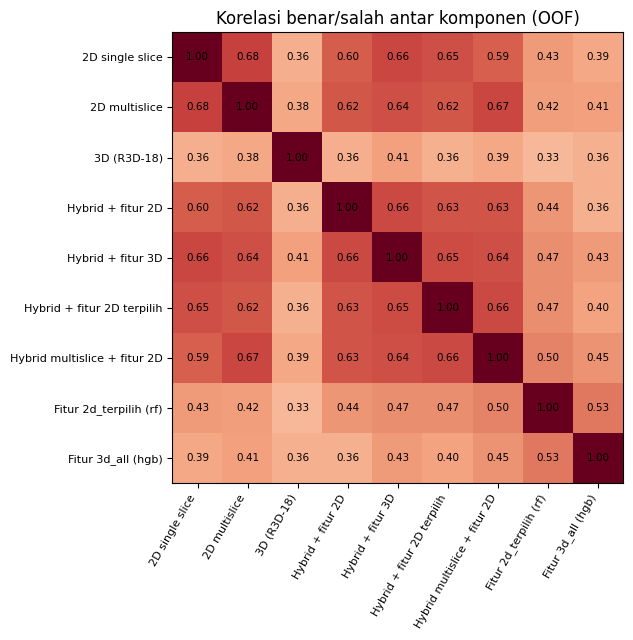

In [16]:
# Seberapa berbeda kesalahan antar komponen? (korelasi benar/salah di OOF; makin rendah, makin berguna untuk ensemble)
correct = pd.DataFrame({c: (OOF[c].argmax(1) == y_tv).astype(int) for c in COMP})
fig, ax = plt.subplots(figsize=(8, 6.5))
M = correct.corr().values
ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(COMP)):
    for j in range(len(COMP)):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
ax.set_xticks(range(len(COMP))); ax.set_xticklabels(COMP, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(COMP))); ax.set_yticklabels(COMP, fontsize=8)
ax.set_title("Korelasi benar/salah antar komponen (OOF)"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "v6_korelasi_komponen.png"), dpi=150); plt.show()

## 10. Cara 1: ensemble lintas pendekatan

Semua kombinasi komponen (rata-rata probabilitas, bobot sama) dinilai dengan macro-F1 OOF. Kombinasi dipilih dengan aturan
one-SE (kalau selisih dengan yang terbaik < 1 sd antar fold, pilih yang komponennya paling sedikit).

Supaya skor CV-nya jujur, proses pemilihan juga dijalankan secara **nested**: untuk tiap fold, kombinasi dipilih hanya dari 4 fold lain,
lalu dinilai di fold yang disisihkan.

In [17]:
from itertools import combinations
SUBSETS = [s for n in range(1, len(COMP) + 1) for s in combinations(COMP, n)]

def subset_scores(mask):
    """Rata-rata dan sd macro-F1 per fold untuk semua subset, hanya memakai fold di `mask`."""
    folds = [k for k in range(5) if mask[k]]
    rows = []
    for s in SUBSETS:
        P = np.mean([OOF[c] for c in s], 0)
        f = [macro_f1(y_tv[fold_of[trval] == k], P[fold_of[trval] == k].argmax(1)) for k in folds]
        rows.append((s, np.mean(f), np.std(f)))
    return rows

def pick_subset(rows):
    best = max(rows, key=lambda r: r[1])
    elig = [r for r in rows if r[1] >= best[1] - best[2]]
    return min(elig, key=lambda r: (len(r[0]), -r[1]))[0]

t0 = time.time()
all_rows = subset_scores([True] * 5)
ENS = pick_subset(all_rows)
nested_ens = []
for k in range(5):
    s = pick_subset(subset_scores([j != k for j in range(5)]))
    P = np.mean([OOF[c] for c in s], 0)
    nested_ens.append(macro_f1(y_tv[fold_of[trval] == k], P[fold_of[trval] == k].argmax(1)))
best_all = max(all_rows, key=lambda r: r[1])
print(f"{len(SUBSETS)} kombinasi dinilai ({time.time() - t0:.0f}s)")
print("Kombinasi OOF tertinggi:", " + ".join(best_all[0]), f"({best_all[1]:.3f} ± {best_all[2]:.3f})")
print("Ensemble terpilih (one-SE):", " + ".join(ENS))
print(f"CV ensemble terpilih: {np.mean(fold_f1s(np.mean([OOF[c] for c in ENS], 0))):.3f} | "
      f"CV nested (jujur): {np.mean(nested_ens):.3f} ± {np.std(nested_ens):.3f}")
top_sub = pd.DataFrame([dict(kombinasi=" + ".join(s), n=len(s), cv_f1=m, cv_sd=sd) for s, m, sd in all_rows]) \
    .sort_values("cv_f1", ascending=False).head(10).round(3)
top_sub

511 kombinasi dinilai (21s)
Kombinasi OOF tertinggi: 2D single slice + 3D (R3D-18) + Hybrid + fitur 2D + Hybrid + fitur 3D + Hybrid multislice + fitur 2D + Fitur 2d_terpilih (rf) + Fitur 3d_all (hgb) (0.685 ± 0.013)
Ensemble terpilih (one-SE): 2D multislice + Hybrid + fitur 3D + Fitur 2d_terpilih (rf)
CV ensemble terpilih: 0.672 | CV nested (jujur): 0.642 ± 0.029


,kombinasi,n,cv_f1,cv_sd
489,2D single slice + 3D (R3D-18) + Hybrid + fitur...,7,0.685,0.013
419,2D single slice + 3D (R3D-18) + Hybrid + fitur...,6,0.683,0.015
488,2D single slice + 3D (R3D-18) + Hybrid + fitur...,7,0.682,0.015
394,2D single slice + 2D multislice + 3D (R3D-18) ...,6,0.682,0.021
374,3D (R3D-18) + Hybrid + fitur 2D terpilih + Hyb...,5,0.682,0.024
390,2D single slice + 2D multislice + 3D (R3D-18) ...,6,0.681,0.028
430,2D single slice + 3D (R3D-18) + Hybrid + fitur...,6,0.681,0.030
473,2D single slice + 2D multislice + 3D (R3D-18) ...,7,0.680,0.031
400,2D single slice + 2D multislice + 3D (R3D-18) ...,6,0.680,0.020
508,2D single slice + 3D (R3D-18) + Hybrid + fitur...,8,0.680,0.025


## 11. Cara 2: penyesuaian bias per kelas

Macro-F1 memberi bobot sama untuk tiap kelas, padahal recall hypointense dan isointense paling rendah. Probabilitas ensemble
dikalikan dengan faktor per kelas (`P × exp(b)`), dengan `b` dicari dari OOF untuk memaksimalkan macro-F1 (pencarian koordinat,
hyperintense sebagai acuan b = 0). Skor jujurnya juga dihitung nested (b dicari di 4 fold, dinilai di fold ke-5).

In [18]:
GRID = np.round(np.arange(-1.0, 1.0001, 0.05), 2)

def apply_bias(P, b):
    Q = P * np.exp(b)[None]
    return Q / Q.sum(1, keepdims=True)

def fit_bias(P, y, n_round=3):
    b = np.zeros(4)
    for _ in range(n_round):
        for c in [1, 2, 3]:
            scores = []
            for g in GRID:
                bb = b.copy(); bb[c] = g
                scores.append(macro_f1(y, apply_bias(P, bb).argmax(1)))
            best = np.max(scores)
            cands = [g for g, s_ in zip(GRID, scores) if s_ >= best - 1e-9]
            b[c] = min(cands, key=abs)                       # kalau seri, pilih koreksi terkecil
    return b

P_ens_oof = np.mean([OOF[c] for c in ENS], 0)
BIAS = fit_bias(P_ens_oof, y_tv)
nested_bias = []
for k in range(5):
    tr_m, te_m = fold_of[trval] != k, fold_of[trval] == k
    s = pick_subset(subset_scores([j != k for j in range(5)]))       # ensemble juga dipilih tanpa fold k
    P = np.mean([OOF[c] for c in s], 0)
    b = fit_bias(P[tr_m], y_tv[tr_m])
    nested_bias.append(macro_f1(y_tv[te_m], apply_bias(P[te_m], b).argmax(1)))
print("Faktor bias per kelas exp(b):", dict(zip(SIG_CLASSES, np.round(np.exp(BIAS), 2))))
print(f"CV nested ensemble + bias: {np.mean(nested_bias):.3f} ± {np.std(nested_bias):.3f} "
      f"(per fold: {' / '.join(f'{x:.3f}' for x in nested_bias)})")
rec = pd.DataFrame({"recall sebelum": [((P_ens_oof.argmax(1) == c) & (y_tv == c)).sum() / (y_tv == c).sum() for c in range(4)],
                    "recall sesudah": [((apply_bias(P_ens_oof, BIAS).argmax(1) == c) & (y_tv == c)).sum() / (y_tv == c).sum() for c in range(4)]},
                   index=SIG_CLASSES).round(3)
print("\nRecall OOF per kelas (non-nested, hanya ilustrasi):"); print(rec.to_string())

Faktor bias per kelas exp(b): {'hyperintense': np.float64(1.0), 'hypointense': np.float64(0.95), 'isointense': np.float64(1.0), 'mixed': np.float64(1.22)}
CV nested ensemble + bias: 0.650 ± 0.019 (per fold: 0.633 / 0.644 / 0.660 / 0.683 / 0.632)

Recall OOF per kelas (non-nested, hanya ilustrasi):
              recall sebelum  recall sesudah
hyperintense           0.780           0.748
hypointense            0.602           0.566
isointense             0.641           0.647
mixed                  0.683           0.735


## 12. Cara 4: training ulang di train+val

Komponen deep di ensemble terpilih dilatih ulang dengan **semua data train+val** (919 data, +22%), tanpa early stopping.
Jumlah epoch = median epoch terbaik di 5-fold CV komponen itu. 2 seed per komponen. Model fitur juga di-fit ulang di train+val.

In [19]:
FULL_SEEDS = [7, 99]
full_split = dict(train=trval, val=np.array([], int), test=split_idx["test"])
FULLP = {}
for c in ENS:
    if c in EXPS:
        n_ep = int(np.median([np.argmax([h["val_f1"] for h in r["history"]]) + 1 for r in CVRUNS[c]]))
        n_ep = max(n_ep, 5)
        runs = [train_run(EXPS[c], s, split=full_split, tag=f"__full{n_ep}", fixed_epochs=n_ep) for s in FULL_SEEDS]
        FULLP[c] = np.mean([np.array(r["eval"]["test"]["p_sig"]) for r in runs], 0)
        print(f"{c}: {n_ep} epoch")
    else:
        fset, mname = re.match(r"Fitur (\S+) \((\w+)\)", c).groups()
        m = FEAT_MODELS[mname]().fit(fmat(fset)[trval], y_sig[trval])
        FULLP[c] = m.predict_proba(fmat(fset)[split_idx["test"]])

vit_win4__seed=7__full12: 12 ep, 0.7 min, 4 s/ep, infer 16.8 ms/pasien | val nan test 0.568
vit_win4__seed=99__full12: 12 ep, 0.7 min, 4 s/ep, infer 16.8 ms/pasien | val nan test 0.600
2D multislice: 12 epoch
vit_old+3d_all__seed=7__full8: 8 ep, 0.5 min, 4 s/ep, infer 5.1 ms/pasien | val nan test 0.552
vit_old+3d_all__seed=99__full8: 8 ep, 0.5 min, 4 s/ep, infer 5.0 ms/pasien | val nan test 0.528
Hybrid + fitur 3D: 8 epoch


## 13. Hasil akhir di data test (dilihat sekali, semua keputusan sudah diambil dari CV)

Model final ditetapkan **sebelum** melihat test: ensemble terpilih + bias kelas, dengan probabilitas test = rata-rata model fold,
model seed utama, dan model train+val. Baris lain hanya untuk melihat kontribusi tiap langkah.

In [20]:
yt = y_sig[split_idx["test"]]
P_base = np.mean([np.array(r["eval"]["test"]["p_sig"]) for r in MAIN["2D single slice"]], 0)
P_ens = np.mean([TESTP[c] for c in ENS], 0)
P_ens_full = np.mean([(TESTP[c] * 8 + FULLP[c] * 2) / 10 if c in EXPS else (TESTP[c] + FULLP[c]) / 2 for c in ENS], 0)
P_final = apply_bias(P_ens_full, BIAS)
base_cv = np.mean(fold_f1s(OOF["2D single slice"]))
steps = [
    ("Baseline: 2D single slice (3 seed)", P_base, base_cv, np.nan),
    ("+ Cara 1: ensemble terpilih", P_ens, np.mean(nested_ens), np.std(nested_ens)),
    ("+ Cara 2: bias per kelas", apply_bias(P_ens, BIAS), np.mean(nested_bias), np.std(nested_bias)),
    ("+ Cara 4: + model train+val  = FINAL", P_final, np.mean(nested_bias), np.std(nested_bias)),
]
res6 = pd.DataFrame([dict(langkah=n, cv_f1=cv, cv_sd=sd, test_f1=macro_f1(yt, P.argmax(1)), test_acc=accuracy_score(yt, P.argmax(1)),
                          **{f"recall_{c[:5]}": ((P.argmax(1) == i) & (yt == i)).sum() / (yt == i).sum() for i, c in enumerate(SIG_CLASSES)})
                     for n, P, cv, sd in steps]).round(3)
res6["capai_0.65_test"] = np.where(res6.test_f1 >= TARGET_F1, "ya", "belum")
res6.to_csv(os.path.join(OUT_DIR, "v6_hasil.csv"), index=False)
print("Komponen ensemble final:", " + ".join(ENS))
print("cv_f1 baseline = CV biasa; baris lain = CV nested (jujur).")
res6

Komponen ensemble final: 2D multislice + Hybrid + fitur 3D + Fitur 2d_terpilih (rf)
cv_f1 baseline = CV biasa; baris lain = CV nested (jujur).


,langkah,cv_f1,cv_sd,test_f1,test_acc,recall_hyper,recall_hypoi,recall_isoin,recall_mixed,capai_0.65_test
0,Baseline: 2D single slice (3 seed),0.622,NaN,0.601,0.620,0.597,0.500,0.517,0.750,belum
1,+ Cara 1: ensemble terpilih,0.642,0.029,0.593,0.620,0.645,0.458,0.517,0.714,belum
2,+ Cara 2: bias per kelas,0.650,0.019,0.584,0.620,0.613,0.375,0.517,0.786,belum
3,+ Cara 4: + model train+val = FINAL,0.650,0.019,0.580,0.614,0.597,0.375,0.517,0.786,belum


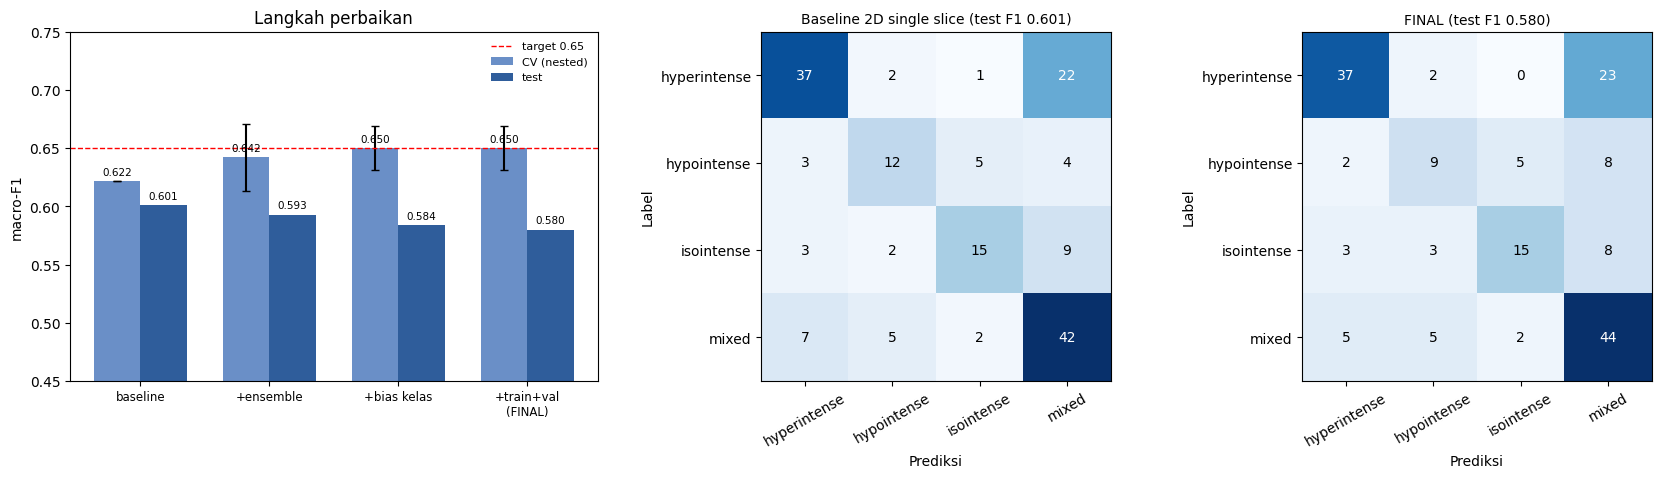

              precision    recall  f1-score   support

hyperintense      0.787     0.597     0.679        62
 hypointense      0.474     0.375     0.419        24
  isointense      0.682     0.517     0.588        29
       mixed      0.530     0.786     0.633        56

    accuracy                          0.614       171
   macro avg      0.618     0.569     0.580       171
weighted avg      0.641     0.614     0.612       171



In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
ax = axes[0]; xx = np.arange(len(res6))
ax.bar(xx - 0.18, res6.cv_f1, 0.36, yerr=res6.cv_sd.fillna(0), capsize=3, color="#6a8fc7", label="CV (nested)")
ax.bar(xx + 0.18, res6.test_f1, 0.36, color="#2f5d9b", label="test")
ax.axhline(TARGET_F1, color="r", ls="--", lw=1, label=f"target {TARGET_F1}")
for i_, (a_, b_) in enumerate(zip(res6.cv_f1, res6.test_f1)):
    ax.text(i_ - 0.18, a_ + 0.005, f"{a_:.3f}", ha="center", fontsize=7.5); ax.text(i_ + 0.18, b_ + 0.005, f"{b_:.3f}", ha="center", fontsize=7.5)
ax.set_xticks(xx); ax.set_xticklabels(["baseline", "+ensemble", "+bias kelas", "+train+val\n(FINAL)"], fontsize=8.5)
ax.set_ylim(0.45, 0.75); ax.set_ylabel("macro-F1"); ax.legend(frameon=False, fontsize=8); ax.set_title("Langkah perbaikan")
for ax, (lab, P) in zip(axes[1:], [("Baseline 2D single slice", P_base), ("FINAL", P_final)]):
    cm = confusion_matrix(yt, P.argmax(1), labels=range(4))
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(SIG_CLASSES, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(SIG_CLASSES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label"); ax.set_title(f"{lab} (test F1 {macro_f1(yt, P.argmax(1)):.3f})", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v6_hasil.png"), dpi=150); plt.show()

print(classification_report(yt, P_final.argmax(1), target_names=SIG_CLASSES, digits=3, zero_division=0))

## 14. Top-2 confidence + kalibrasi (final vs baseline)
Suhu kalibrasi dipilih dari OOF (bukan test).

In [22]:
HYPER, HYPO, ISO, MIXED = SIG_CLASSES
ORD = {HYPO: 0, ISO: 1, HYPER: 2}
def apply_T(P, T):
    L = np.log(P + 1e-9) / T; L -= L.max(1, keepdims=True); Q = np.exp(L); return Q / Q.sum(1, keepdims=True)
def nll(P, y):
    return -np.log(P[np.arange(len(y)), y] + 1e-9).mean()
def ece(P, y, bins=10):
    conf, pred = P.max(1), P.argmax(1); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e
def mentioned(sentence):
    s_ = str(sentence).lower(); m = set()
    if re.search(r"\bhyper\w*|\bhigh\b|\bbright\w*", s_): m.add(HYPER)
    if re.search(r"\bhypo\w*|\blow\b|\bdark\w*", s_): m.add(HYPO)
    if re.search(r"\biso\w*", s_): m.add(ISO)
    if re.search(r"\bmix\w*|\bheterogen\w*", s_): m.add(MIXED)
    return m
def relevance(a, b, sentence, true):
    R = mentioned(sentence) | {true}
    if len(R & {HYPER, HYPO, ISO}) >= 2: R.add(MIXED)
    if a in R and b in R: return "relevan"
    if a in ORD and b in ORD and abs(ORD[a] - ORD[b]) == 1: return "relevan"
    if MIXED in (a, b) and (b if a == MIXED else a) in R: return "sebagian"
    return "tidak relevan"

test_df = records.loc[split_idx["test"]].copy()
Ts = np.linspace(0.3, 3.0, 55)
top2_rows = []
for lab, Pt, Po in [("baseline 2D single slice", P_base, OOF["2D single slice"]),
                    ("FINAL", P_final, apply_bias(P_ens_oof, BIAS))]:
    T = float(Ts[np.argmin([nll(apply_T(Po, t_), y_tv) for t_ in Ts])])
    Pc = apply_T(Pt, T); o = np.argsort(-Pc, 1)
    d = test_df.assign(top1=[SIG_CLASSES[i] for i in o[:, 0]], top2=[SIG_CLASSES[i] for i in o[:, 1]])
    d["rel"] = [relevance(a, b, s_, l) for a, b, s_, l in zip(d.top1, d.top2, d.source_sentence, d.signal_label)]
    w = d[d.top1 != d.signal_label]
    top2_rows.append(dict(model=lab, T=T, ece_before=ece(Pt, yt), ece_after=ece(Pc, yt), top1_acc=(d.top1 == d.signal_label).mean(),
                          top2_acc=((d.top1 == d.signal_label) | (d.top2 == d.signal_label)).mean(), salah=len(w),
                          benar_di_posisi2=(w.top2 == w.signal_label).mean(), relevan=(w.rel == "relevan").mean(),
                          sebagian=(w.rel == "sebagian").mean(), tidak_relevan=(w.rel == "tidak relevan").mean()))
top2_df = pd.DataFrame(top2_rows).round(3)
top2_df.to_csv(os.path.join(OUT_DIR, "v6_top2.csv"), index=False)
top2_df

,model,T,ece_before,ece_after,top1_acc,top2_acc,salah,benar_di_posisi2,relevan,sebagian,tidak_relevan
0,baseline 2D single slice,1.35,0.099,0.089,0.620,0.854,65,0.615,0.354,0.385,0.262
1,FINAL,0.85,0.062,0.073,0.614,0.889,66,0.712,0.318,0.455,0.227


## 15. Biaya ensemble & ringkasan
Perkiraan waktu proses 1 pasien untuk model final = baca data sekali + (preprocessing + fitur + model) tiap komponen × jumlah model,
memakai pengukuran per pasien dari v5 (kalau file-nya ada di input).

In [23]:
n_models = {c: (len(CVRUNS[c]) + len(MAIN[c]) + len(FULL_SEEDS)) if c in EXPS else 7 for c in ENS}
lat_est = None
_lat_path = os.path.join(V5_DIR, "v5_waktu_per_pasien.csv") if V5_DIR else None
if _lat_path and os.path.exists(_lat_path):
    L5 = pd.read_csv(_lat_path).set_index("pendekatan")
    name_map = {"2D multislice": "2D multislice (win4)"}
    t_ = L5.baca_data_detik.mean()
    for c in ENS:
        key5 = name_map.get(c, c)
        if c in EXPS and key5 in L5.index:
            t_ += L5.loc[key5, "preprocessing_detik"] + L5.loc[key5, "ekstraksi_fitur_detik"] + L5.loc[key5, "model_detik"] * n_models[c]
        elif c in EXPS:      # hybrid multislice + fitur: preprocessing & model seperti multislice, fitur seperti hybrid 2D
            t_ += (L5.loc["2D multislice (win4)", "preprocessing_detik"] + L5.loc["Hybrid + fitur 2D", "ekstraksi_fitur_detik"]
                   + L5.loc["2D multislice (win4)", "model_detik"] * n_models[c])
        else:
            dim = c.split()[1][:2].upper()
            row = [r for r in L5.index if r.startswith(f"Fitur {dim}")][0]
            t_ += L5.loc[row, "ekstraksi_fitur_detik"] + L5.loc[row, "model_detik"] * n_models[c]
    lat_est = float(t_)
    print(f"Perkiraan waktu proses 1 pasien untuk model final: {lat_est:.2f} s "
          f"(baseline 1 model: {L5.loc['2D single slice', 'total_detik']:.3f} s)")
print("Jumlah model di ensemble final:", n_models, "| total", sum(n_models.values()))

summary = dict(
    target_f1=TARGET_F1, ensemble=list(ENS), bias=dict(zip(SIG_CLASSES, np.exp(BIAS).round(3).tolist())),
    komponen=json.loads(comp_df.to_json(orient="records")), top_kombinasi=json.loads(top_sub.to_json(orient="records")),
    cv_nested_ensemble=[float(np.mean(nested_ens)), float(np.std(nested_ens))],
    cv_nested_final=[float(np.mean(nested_bias)), float(np.std(nested_bias))], nested_per_fold=nested_bias,
    hasil=json.loads(res6.to_json(orient="records")), top2=json.loads(top2_df.to_json(orient="records")),
    n_model=n_models, waktu_per_pasien_detik=lat_est,
)
json.dump(summary, open(os.path.join(OUT_DIR, "v6_summary.json"), "w"), indent=2, default=float)
print(res6[["langkah", "cv_f1", "cv_sd", "test_f1", "capai_0.65_test"]].to_string(index=False))

Perkiraan waktu proses 1 pasien untuk model final: 1.08 s (baseline 1 model: 0.057 s)
Jumlah model di ensemble final: {'2D multislice': 10, 'Hybrid + fitur 3D': 10, 'Fitur 2d_terpilih (rf)': 7} | total 27
                             langkah  cv_f1  cv_sd  test_f1 capai_0.65_test
  Baseline: 2D single slice (3 seed)  0.622    NaN    0.601           belum
         + Cara 1: ensemble terpilih  0.642  0.029    0.593           belum
            + Cara 2: bias per kelas  0.650  0.019    0.584           belum
+ Cara 4: + model train+val  = FINAL  0.650  0.019    0.580           belum
